<a href="https://colab.research.google.com/github/theinquisitorjif/redtideml/blob/main/redtidelinml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model

In [2]:
df = pd.read_csv('/content/chlorophyll_red_tide_data.csv')

In [3]:
df

,chlorophyll_a_ug_L,red_tide_cell_intensity_cells_L
0,18.789552,188330.75460
1,47.540644,473911.40210
2,36.626498,366723.78080
3,29.973058,289792.73900
4,7.885330,77754.94214
...,...,...
95,24.740400,243324.95120
96,26.184368,261458.17330
97,21.434297,216048.72800
98,1.368414,15067.59824


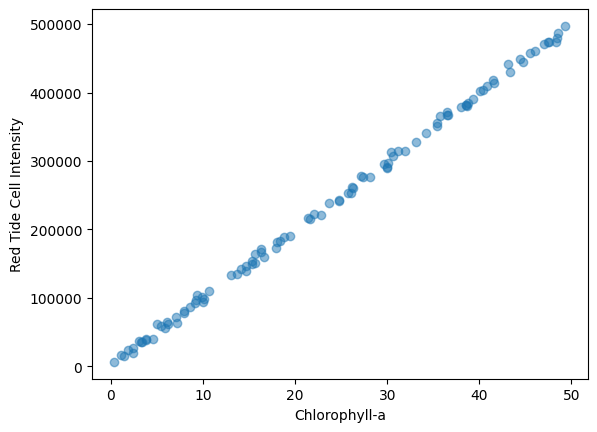

In [7]:
plt.xlabel('Chlorophyll-a')
plt.ylabel('Red Tide Cell Intensity')
plt.scatter(df.chlorophyll_a_ug_L, df.red_tide_cell_intensity_cells_L, alpha=.5)


In [18]:
df.feature_names = ['chlorophyll_a_ug_L']
df.target_names = ['red_tide_cell_intensity_cells_L']


/tmp/ipython-input-18-187302835.py:1: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.feature_names = ['chlorophyll_a_ug_L']
/tmp/ipython-input-18-187302835.py:2: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.target_names = ['red_tide_cell_intensity_cells_L']


In [19]:
df.feature_names


['chlorophyll_a_ug_L']

In [20]:
df.target_names

['red_tide_cell_intensity_cells_L']

In [21]:
X = df.drop('red_tide_cell_intensity_cells_L', axis='columns')
y = df.red_tide_cell_intensity_cells_L

In [24]:
y

,red_tide_cell_intensity_cells_L
0,188330.75460
1,473911.40210
2,366723.78080
3,289792.73900
4,77754.94214
...,...
95,243324.95120
96,261458.17330
97,216048.72800
98,15067.59824


In [26]:
X.shape, y.shape


((100, 1), (100,))

In [28]:
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1)

In [31]:
X_train.shape, y_train.shape

((90, 1), (90,))

In [32]:
model = linear_model.LinearRegression()


In [33]:
model.fit(X_train, y_train)

LinearRegression()

In [34]:
X_test

,chlorophyll_a_ug_L
26,10.063722
68,3.820077
48,27.380843
36,15.300227
0,18.789552
33,47.449388
25,39.280280
51,38.779128
10,1.127166
74,35.372181


In [35]:
y_pred = model.predict(X_test)

In [43]:
y_pred, y_test

(array([101168.90968159,  39000.98172822, 273595.37066543, 153308.75870581,
        188051.94308457, 473417.74375388, 392077.9911954 , 387088.01828164,
         12187.68621324, 353165.07528421]),
 26     98923.64471
 68     39500.18517
 48    276742.71490
 36    153303.42190
 0     188330.75460
 33    474121.65350
 25    390699.57810
 51    384959.79020
 10     15848.67324
 74    354974.27880
 Name: red_tide_cell_intensity_cells_L, dtype: float64)

In [37]:
print('Coefficients:', model.coef_)
print('Intercept:', model.intercept_)
print('Mean squared error (MSE): %.2f'
      % mean_squared_error(y_test, y_pred))
print('Coefficient of determination (R^2): %.2f'
      % r2_score(y_test, y_pred))

Coefficients: [9956.99336471]
Intercept: 964.4991917074076
Mean squared error (MSE): 3887486.87
Coefficient of determination (R^2): 1.00


<Axes: xlabel='red_tide_cell_intensity_cells_L'>

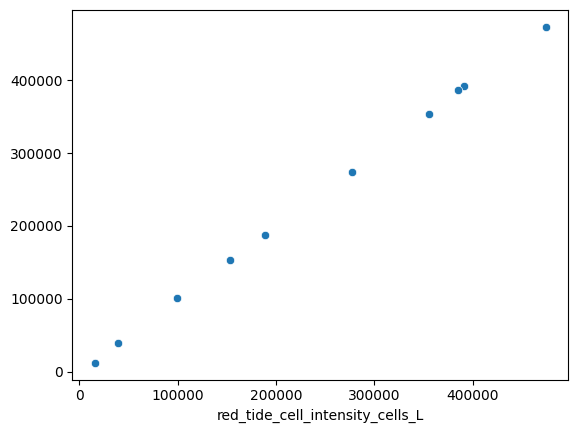

In [38]:
sns.scatterplot(x=y_test, y=y_pred)

In [42]:
y_pred

array([101168.90968159,  39000.98172822, 273595.37066543, 153308.75870581,
       188051.94308457, 473417.74375388, 392077.9911954 , 387088.01828164,
        12187.68621324, 353165.07528421])

In [41]:
y[:50]

,red_tide_cell_intensity_cells_L
0,188330.75460
1,473911.40210
2,366723.78080
3,289792.73900
4,77754.94214
5,80626.82851
6,37373.19270
7,430630.54570
8,296913.92280
9,351819.43110
